# 02 — Predictive coding on image patches

Fit a two-level reconstruction model to synthetic image patches. Inference updates latent activities; learning updates the dictionary. Inspect held-out reconstructions and learned bases. The calculation illustrates a predictive-coding proposal and does not identify a cortical mechanism.

Section references in the suggested reading refer to the [August background paper](../../paper/background/august-perspective.pdf). For the current talk, use the [slide-to-resource guide](../../talk/resources.md).


In [1]:
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = os.environ.get("BRAINSMODELS_REPO_URL",
                      "https://github.com/arvidl/brains-to-models-publication.git")
COLAB_ROOT = Path("/content/brains-to-models")

if "google.colab" in sys.modules:
    if not (COLAB_ROOT / "code" / "src" / "brainsmodels").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(COLAB_ROOT)])
    root = COLAB_ROOT
else:
    here = Path.cwd().resolve()
    root = here.parents[1] if here.name == "notebooks" else here

src = root / "code" / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.predictive_coding import (
    HierarchicalPredictiveCoding,
    PatchDataset,
    render_paper_figure,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

repo root: CHECKOUT
seed: 7


## Patches from 1/f images

Natural scenes have a roughly $1/f$ amplitude spectrum. We synthesize that statistic, mix in a few windowed gratings so a small dictionary has oriented structure to find, cut $8\times 8$ patches, contrast-normalize them, and ZCA-whiten — the usual preprocessing for sparse-coding / predictive-coding demos.

(2400, 64) whitened training patches


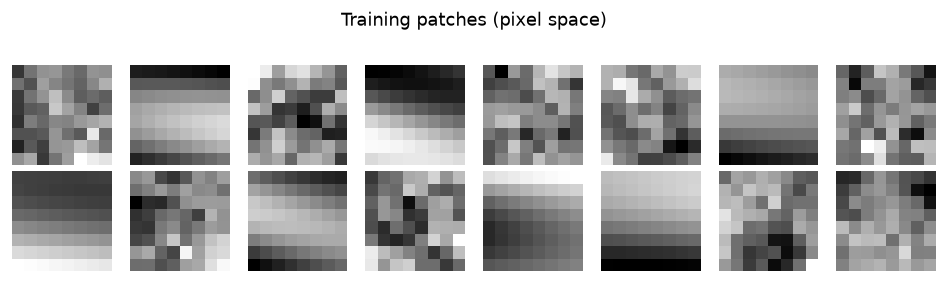

In [2]:
data = PatchDataset.from_pink_noise(seed=SEED)
print(data.train.shape, "whitened training patches")

fig, axes = plt.subplots(2, 8, figsize=(8, 2.4))
for ax, patch in zip(axes.ravel(), data.train_pixel[:16]):
    vmax = np.max(np.abs(patch)) + 1e-8
    ax.imshow(patch.reshape(data.patch_size, data.patch_size), cmap="gray",
              vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_axis_off()
fig.suptitle("Training patches (pixel space)", fontsize=11)
fig.tight_layout()
plt.show()

## Two-level Rao–Ballard dynamics

Level 1 predicts pixels ($\hat{x} = U_1 r_1$); level 2 predicts $r_1$ ($\hat{r}_1 = U_2 r_2$). Errors $e_0 = x - \hat{x}$ and $e_1 = r_1 - \hat{r}_1$ update the representations, then the weights:

$$
\Delta r_1 \propto U_1^\top e_0 - e_1, \qquad
\Delta r_2 \propto U_2^\top e_1 - \lambda r_2, \qquad
\Delta U \propto e\, r^\top.
$$

epoch 01/25  recon MSE 0.2998
epoch 02/25  recon MSE 0.2507
epoch 03/25  recon MSE 0.2167


epoch 04/25  recon MSE 0.1951
epoch 05/25  recon MSE 0.1814


epoch 06/25  recon MSE 0.1723
epoch 07/25  recon MSE 0.1663
epoch 08/25  recon MSE 0.1624
epoch 09/25  recon MSE 0.1601


epoch 10/25  recon MSE 0.1588
epoch 11/25  recon MSE 0.1580
epoch 12/25  recon MSE 0.1576


epoch 13/25  recon MSE 0.1573
epoch 14/25  recon MSE 0.1571


epoch 15/25  recon MSE 0.1569
epoch 16/25  recon MSE 0.1568
epoch 17/25  recon MSE 0.1567
epoch 18/25  recon MSE 0.1565


epoch 19/25  recon MSE 0.1565
epoch 20/25  recon MSE 0.1564
epoch 21/25  recon MSE 0.1563


epoch 22/25  recon MSE 0.1563
epoch 23/25  recon MSE 0.1562


epoch 24/25  recon MSE 0.1561
epoch 25/25  recon MSE 0.1560


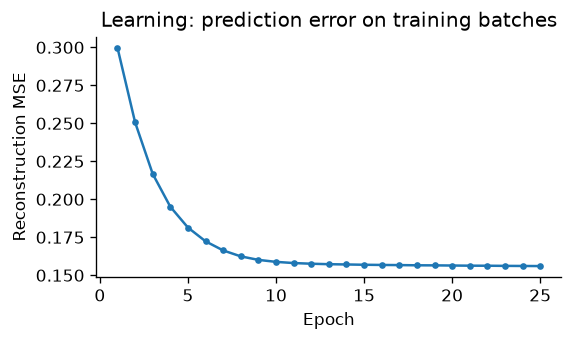

In [3]:
model = HierarchicalPredictiveCoding(n_input=data.train.shape[1], seed=SEED)
history = model.train(data.train, n_epochs=25, seed=SEED)

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(np.arange(1, len(history) + 1), history, marker=".")
ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction MSE")
ax.set_title("Learning: prediction error on training batches")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Paper figure

Learned first-level bases, then three held-out patches as inference explains them away. Residual MSE is in the whitened space the network actually sees.

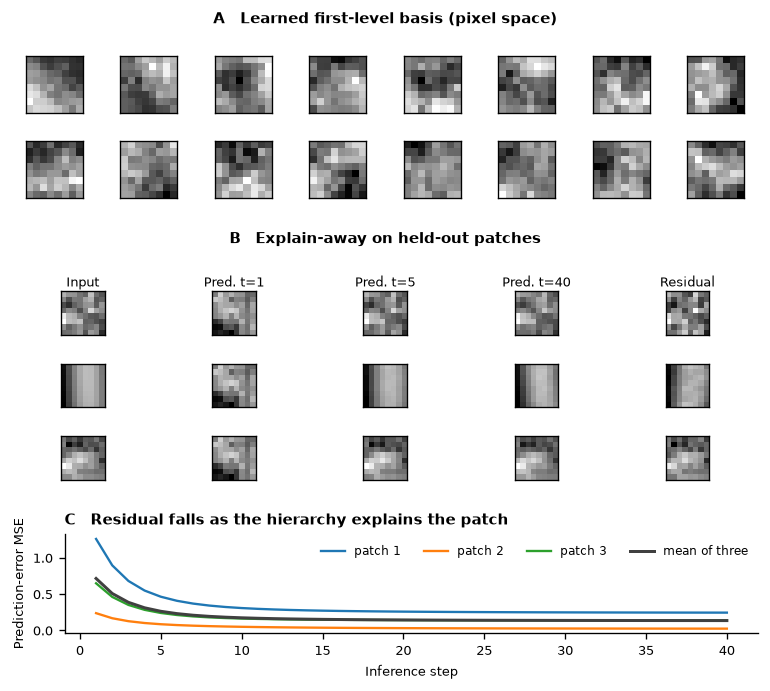

wrote CHECKOUT/paper/figures/predictive_coding_patches.pdf
wrote CHECKOUT/paper/figures/predictive_coding_patches.png
wrote CHECKOUT/paper/figures/predictive_coding_patches.pdf


In [4]:
fig = render_paper_figure(model, data)
plt.show()

out = write_figure(model, data, root / "paper" / "figures")
print("wrote", out)

## Interpret the calculation

Describe the changes you observe under parameter or input interventions. Separate properties guaranteed by the equations from empirical behavior in this run and from biological interpretations.


### Exercises

1. **Inference is not learning.** Panel C is the residual falling *inside one patch*, with the weights held fixed. Freeze a trained network, then reconstruct a held-out patch after 1, 5, and 40 inference steps. Then take the *untrained* initial weights and do the same. How much of the falling residual is the hierarchy explaining the patch, and how much is just “any basis plus enough iterations”?

<!-- solution-box: 02_1_inference_not_learning.py -->
<details>
<summary><strong>Show solution</strong> — Inference is not learning</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02_1_inference_not_learning.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.predictive_coding import HierarchicalPredictiveCoding, PatchDataset
data = PatchDataset.from_pink_noise(n_train=500, n_test=16, n_images=8, seed=SEED)
x = data.test[0]
fresh = HierarchicalPredictiveCoding(n_input=x.size, seed=SEED)
trained = HierarchicalPredictiveCoding(n_input=x.size, seed=SEED)
trained.train(data.train, n_epochs=6, n_infer=20, seed=SEED)

def curve(model, steps=40):
    _, mse = model.infer_history(x, n_steps=steps)
    return np.asarray(mse)

c0, c1 = curve(fresh), curve(trained)
print(f"untrained  MSE t=1 {c0[0]:.3f}  t=40 {c0[-1]:.3f}")
print(f"trained    MSE t=1 {c1[0]:.3f}  t=40 {c1[-1]:.3f}")
print(f"drop untrained {c0[0] - c0[-1]:.3f}   drop trained {c1[0] - c1[-1]:.3f}")

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(c0, label="untrained weights")
ax.plot(c1, label="after 6 epochs")
ax.set_xlabel("inference step")
ax.set_ylabel("prediction-error MSE")
ax.legend(frameon=False)
ax.set_title("Same infer loop; only the descending weights changed")
plt.tight_layout()
plt.show()
print('Inference changes the current representation with weights fixed. Compare the measured residuals for trained and initial weights to separate iterative fitting from the effect of learning.')
```

</details>
<!-- /solution-box -->


2. **One level.** The network is two-level: $r_2$ predicts $r_1$, $r_1$ predicts pixels. Train a copy with `n_level2=1` (almost no higher code) and one with the default 12 units, same data and seed. Compare held-out reconstruction MSE after the same number of inference steps. What does the higher level buy on these 8×8 patches, and what can it not buy?

<!-- solution-box: 02_2_one_level.py -->
<details>
<summary><strong>Show solution</strong> — One level</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02_2_one_level.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.predictive_coding import HierarchicalPredictiveCoding, PatchDataset
data = PatchDataset.from_pink_noise(n_train=500, n_test=24, n_images=8, seed=SEED)
shallow = HierarchicalPredictiveCoding(n_input=data.train.shape[1], n_level2=1, seed=SEED)
deep = HierarchicalPredictiveCoding(n_input=data.train.shape[1], n_level2=12, seed=SEED)
shallow.train(data.train, n_epochs=6, n_infer=20, seed=SEED)
deep.train(data.train, n_epochs=6, n_infer=20, seed=SEED + 1)

def recon_mse(model):
    _, _, tr = model.infer(data.test, n_steps=40, record=True)
    return float(np.mean(tr.error**2))

print(f"n_level2=1   held-out MSE {recon_mse(shallow):.4f}")
print(f"n_level2=12  held-out MSE {recon_mse(deep):.4f}")
print('Compare held-out reconstruction errors at the same inference budget. This tests the added latent capacity on these patches; it does not isolate the organization of cortical processing.')
```

</details>
<!-- /solution-box -->


3. **Skip the whitening.** The descending weights are learned in ZCA-whitened coordinates, then mapped back to pixels for panel A. Train the same architecture on the *unwhitened* pixel patches (`data.train_pixel`). Do the first-level columns still look localized and oriented when you plot them as 8×8 images? What did whitening buy, and what did it not invent?

<!-- solution-box: 02_3_skip_the_whitening.py -->
<details>
<summary><strong>Show solution</strong> — Skip the whitening</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02_3_skip_the_whitening.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.predictive_coding import HierarchicalPredictiveCoding, PatchDataset
data = PatchDataset.from_pink_noise(n_train=500, n_test=16, n_images=8, seed=SEED)
pix = HierarchicalPredictiveCoding(n_input=data.train_pixel.shape[1], seed=SEED)
zca = HierarchicalPredictiveCoding(n_input=data.train.shape[1], seed=SEED)
pix.train(data.train_pixel, n_epochs=6, n_infer=20, seed=SEED)
zca.train(data.train, n_epochs=6, n_infer=20, seed=SEED)

rf_pix = pix.U1
rf_zca = data.whitening.to_pixel_basis(zca.U1)
energy = rf_zca.reshape(data.patch_size, data.patch_size, -1).var(axis=(0, 1))
order = np.argsort(energy)[::-1][:8]

fig, axes = plt.subplots(2, 8, figsize=(9.5, 2.8))
for col, i in enumerate(order):
    for row, bank, name in ((0, rf_pix, "pixels"), (1, rf_zca, "ZCA→pixels")):
        patch = bank[:, i].reshape(data.patch_size, data.patch_size)
        vmax = np.max(np.abs(patch)) + 1e-8
        axes[row, col].imshow(patch, cmap="gray", vmin=-vmax, vmax=vmax)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(name, fontsize=8)
fig.suptitle("Whitening changes the coordinates the Hebbian rule sees")
plt.tight_layout()
plt.show()
print('Whitening changes the input covariance and hence the learning problem. Compare the learned columns and reconstruction errors before attributing their appearance to the update rule.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What differs between inference and learning in this model?

2. What does decreasing reconstruction error establish?

3. How does whitening affect the experiment?

4. What is a fair comparison of one-level and two-level models?

5. How could a cortical interpretation be tested?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Rao, R. P. N., and Ballard, D. H. (1999).** [*Predictive coding in the visual cortex: a functional interpretation of some extra-classical receptive-field effects*](https://homes.cs.washington.edu/~rao/Rao-Ballard-NN-1999.pdf). *Nature Neuroscience* 2, 79–87. Author PDF.
2. **Friston, K. (2010).** [*The free-energy principle: a unified brain theory?*](https://www.fil.ion.ucl.ac.uk/~karl/The%20free-energy%20principle%20A%20unified%20brain%20theory.pdf). *Nature Reviews Neuroscience* 11, 127–138. Author PDF.
3. **Clark, A. (2013).** [*Whatever next? Predictive brains, situated agents, and the future of cognitive science*](https://doi.org/10.1017/S0140525X12000477). *Behavioral and Brain Sciences* 36(3), 181–204.
4. **Salvatori, T., et al. (2023).** [*A Survey on Brain-inspired Deep Learning via Predictive Coding*](https://arxiv.org/abs/2308.07870). arXiv:2308.07870 (journal version: *Neural Networks* 195, 108161, 2026).
5. **Schrimpf, M., et al. (2021).** [*The neural architecture of language: Integrative modeling converges on predictive processing*](https://www.pnas.org/doi/10.1073/pnas.2105646118). *PNAS* 118(45), e2105646118.
6. **Seth, A. (2021).** [*Being You: A New Science of Consciousness*](https://www.anilseth.com/being-you). Faber & Faber. Author page.
